<a href="https://colab.research.google.com/github/dynexian/acoustic-gatekeeper/blob/main/acoustic_drone_detection_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Acoustic Drone Detection

This project detects the presence of drones using acoustic data.

In this section, we extract the dataset and process the raw audio files. The audio is converted into Mel-Frequency Cepstral Coefficients (MFCCs), which act as the feature representations for the machine learning model.

In [4]:
import os
import zipfile
import librosa
import numpy as np
import tensorflow as tf
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Extract dataset to local storage
zip_path = '/content/drive/MyDrive/Master_Dataset.zip'
local_dataset_path = '/content/Master_Dataset'

if not os.path.exists(local_dataset_path):
    print("Extracting files...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/')
    print("Extraction complete.")

# MFCC Extraction function
def load_and_convert_data(base_dir, split_name):
    X, y = [], []
    split_dir = os.path.join(base_dir, split_name)
    classes = {'Background': 0, 'Drone': 1}

    for class_name, label in classes.items():
        class_dir = os.path.join(split_dir, class_name)
        files = os.listdir(class_dir)

        print(f"Converting {split_name}/{class_name} ({len(files)} files)...")
        for file in files:
            filepath = os.path.join(class_dir, file)
            audio, sr = librosa.load(filepath, sr=16000)
            mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=40)
            X.append(mfcc.T)
            y.append(label)

    return np.array(X), np.array(y)

print("Processing training data...")
X_train, y_train = load_and_convert_data(local_dataset_path, 'Train')

print("\nProcessing testing data...")
X_test, y_test = load_and_convert_data(local_dataset_path, 'Test')

print(f"\nTraining data shape: {X_train.shape}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Processing training data...
Converting Train/Background (9097 files)...
Converting Train/Drone (4325 files)...

Processing testing data...
Converting Test/Background (2400 files)...
Converting Test/Drone (1646 files)...

Training data shape: (13422, 32, 40)


## Convolutional Neural Network Architecture

Here we define a 1D Convolutional Neural Network (CNN) to classify the MFCC features. The model uses convolutional layers to extract frequency patterns over time, followed by max pooling and dense layers to output a binary classification (Drone vs. Background). The cell below handles compiling, training, and plotting the training history.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 30, 32)         │         3,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 13, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,785 (135.88 KB)

 Trainable params: 34,785 (135.88 KB)

 Non-trainable params: 0 (0.00 B)


Starting model training...
Epoch 1/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8993 - loss: 0.4776 - val_accuracy: 0.9456 - val_loss: 0.1892
Epoch 2/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9585 - loss: 0.1209 - val_accuracy: 0.9558 - val_loss: 0.1791
Epoch 3/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9674 - loss: 0.0972 - val_accuracy: 0.9565 - val_loss: 0.1640
Epoch 4/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9732 - loss: 0.0774 - val_accuracy: 0.9671 - val_loss: 0.1388
Epoch 5/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9776 - loss: 0.0617 - val_accuracy: 0.9632 - val_loss: 0.1547
Epoch 6/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9777 - loss: 0.0669 - val_accuracy: 0.9587 - val_loss: 0.1960
Epoch 7/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9812 - loss: 0.0532 - val_accuracy: 0.9637 - val_loss: 0.2046
Epoch 8/20
420/420 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9817 - l

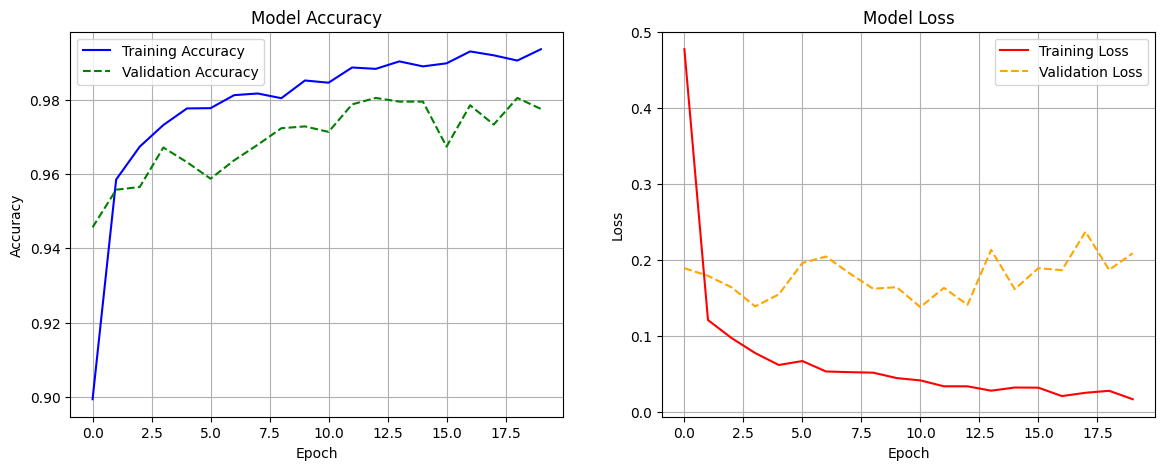

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Define CNN model for audio classification
model = models.Sequential([
    layers.Input(shape=(32, 40)),
    layers.Conv1D(filters=32, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Conv1D(filters=64, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

# Compile model
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

# Train model
print("\nStarting model training...")
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test)
)

# Plot training history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='green', linestyle='--')
ax1.set_title("Model Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True)

ax2.plot(history.history['loss'], label='Training Loss', color='red')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', linestyle='--')
ax2.set_title("Model Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True)

plt.show()


## Evaluation and Inference

With the model trained, we evaluate its performance on the held-out test set. This step generates a confusion matrix and a classification report to review accuracy, precision, and recall. Finally, a short inference simulation tests the model on random audio samples.

Running inference on test set...
127/127 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


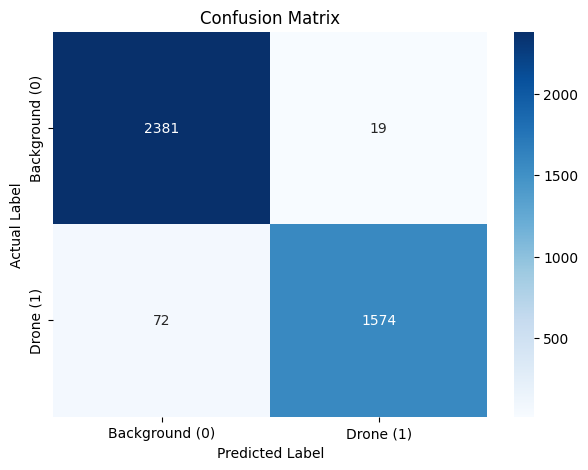


Classification Report:
              precision    recall  f1-score   support

  Background       0.97      0.99      0.98      2400
       Drone       0.99      0.96      0.97      1646

    accuracy                           0.98      4046
   macro avg       0.98      0.97      0.98      4046
weighted avg       0.98      0.98      0.98      4046


Inference Simulation:
Test Audio 3541: [True: Drone     ] | Predict: Drone      | Confidence: 100.00% [Match]
Test Audio 1827: [True: Background] | Predict: Background | Confidence: 100.00% [Match]
Test Audio 1432: [True: Background] | Predict: Background | Confidence: 100.00% [Match]
Test Audio 2364: [True: Background] | Predict: Background | Confidence: 100.00% [Match]
Test Audio 1502: [True: Background] | Predict: Background | Confidence: 100.00% [Match]


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import random

# Generate predictions
print("Running inference on test set...")
try:
    y_pred_probs = model.predict(X_test)
    y_pred_classes = (y_pred_probs > 0.5).astype(int).flatten()

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred_classes)

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Background (0)', 'Drone (1)'],
                yticklabels=['Background (0)', 'Drone (1)'])
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

    # Classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred_classes, target_names=['Background', 'Drone']))

    # Inference simulation
    print("\nInference Simulation:")
    sample_indices = random.sample(range(len(X_test)), 5)

    for idx in sample_indices:
        mfcc_input = X_test[idx]
        actual_label = "Drone" if y_test[idx] == 1 else "Background"
        single_input = np.expand_dims(mfcc_input, axis=0)
        probability = model.predict(single_input, verbose=0)[0][0]

        predicted_label = "Drone" if probability > 0.5 else "Background"
        confidence = probability * 100 if probability > 0.5 else (1 - probability) * 100

        match = "Match" if actual_label == predicted_label else "Mismatch"
        print(f"Test Audio {idx}: [True: {actual_label:<10}] | Predict: {predicted_label:<10} | Confidence: {confidence:.2f}% [{match}]")

except NameError:
    print("Error: Data or model not found. Please ensure you run the data loading and model training cells first.")
